In [1]:
# Imports and globals
%load_ext autoreload
%matplotlib ipympl
%autoreload 2

import numpy as np
import jax.numpy as jnp
from scipy.linalg import sqrtm
from matplotlib import pyplot as plt
from ellipsoids import plot_ellipse, Ellipsoid, plot_projection, sample_from
from typing import Tuple
from CompassGaitWalker import CompassGaitWalker
from diffrax import diffeqsolve, ODETerm, Tsit5, Event, Dopri8, Euler, SaveAt, RESULTS
from equinox import filter_jit
import optimistix as optx
import jax
from jax.lib import xla_bridge
print(xla_bridge.get_backend().platform) # TODO: GPU this
# jax.config.update("jax_disable_jit", True)
import pdb

PLOT = True


/tmp/ipykernel_1166664/1001069775.py:18: DeprecationWarning: jax.lib.xla_bridge.get_backend is deprecated; use jax.extend.backend.get_backend.
  print(xla_bridge.get_backend().platform) # TODO: GPU this


cpu


In [2]:
## Setup system and ODE Solver
sys = CompassGaitWalker(m=5., mh=10., a=0.5, b=0.5, gamma=0.0525) # This has a known limit cycle
x0_nom = np.array([-0.21876908,  0.32376908,  1.8083619 ,  1.49571536]) # This point must be on the guard
assert jnp.abs(sys.guard(0, x0_nom)) < 1e-5 # x0_nom is on guard

term = ODETerm(sys.f)
solver = Dopri8()
# ctrl_func = lambda t, x: 0.0
u = 0.0

cond_fn = sys.guard
root_finder = optx.Newton(5e-7, 5e-7, optx.rms_norm)
event = Event(cond_fn, root_finder, direction=True)

# Step-to-step map of the Compass Gait Walker
# Start on pre-impact state xminus and check next intersection onto guard surface
@filter_jit
def one_step(xm):
    xp = sys.reset(0, xm)
    traj = diffeqsolve(term, solver, t0=0, t1=2, dt0=0.001, y0=xp, args=u, event=event)
    ys = traj.ys

    return ys.flatten()

print(x0_nom)
print(one_step(x0_nom))
print("Test one_step(x0_nom)")
assert jnp.allclose(one_step(x0_nom), x0_nom, atol=5e-4)
assert jnp.abs(sys.guard(0, x0_nom)) < 1e-5 # x0_nom is on guard


print("Test vmapped P")
P_full = jax.vmap(one_step) # Redefine P to be over 

assert jnp.allclose(P_full(x0_nom[np.newaxis, :]), x0_nom, atol=5e-4)

[-0.21876908  0.32376908  1.8083619   1.49571536]
[-0.21877135  0.32377136  1.8080256   1.4957017 ]
Test one_step(x0_nom)
Test vmapped P


In [210]:
## Functions for sampling on guard surface

N = 1000 # Number of samples

# Define 3 vectors that are aligned with the guard surface so we can sample preimpact states
# You can do this automatically with jax.grad or by hand as shown here
c = jnp.array([[1, 1, 0, 0]]).T
guard_surface_chart = jnp.array([[1, -1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]).T

# Randomly sample points uniformly from some rectangular interval in guard surface coordinates
guard_pts = np.random.uniform(-0.005, 0.005, size=(N, 3))

# guard_pts: (N, 3)
def guard_pts_to_full(guard_pts):
    return (guard_surface_chart@guard_pts.T).T + x0_nom

# full pts: (4, N)
def full_pts_to_guard(full_pts):
    pts_guard = (jnp.linalg.inv(jnp.hstack((guard_surface_chart, c)))@(full_pts - x0_nom).T).T
    return pts_guard[..., 0:3]

guard_vmap = jax.vmap(lambda x: sys.guard(0, x.flatten()), 0)
# print(guard_pts_to_full(perturbations).T)

assert guard_pts_to_full(guard_pts).shape == (N, 4)
guard_values = guard_vmap(guard_pts_to_full(guard_pts))
assert jnp.allclose(guard_values, 0, atol=1e-7)

# print(guard_pts)
# print(full_pts_to_guard(guard_pts_to_full(guard_pts)))
assert jnp.allclose(full_pts_to_guard(guard_pts_to_full(guard_pts)), guard_pts, atol=5e-6)

def rollout_sys_to_guard(xm):
    xp = sys.reset(0, xm)
    traj = diffeqsolve(term, solver, t0=0, t1=2, dt0=0.001, y0=xp, args=u, event=event, saveat=SaveAt(steps=1), throw=False, max_steps=8192)
    ts = traj.ts
    ys = traj.ys

    return traj, ts[jnp.isfinite(ts)], ys[jnp.isfinite(ts), :]


In [206]:
# Estimate the eigenvalues of P in the guard chart numerically
perturbation = 1e-6

def one_step_on_guard(xm_guard):
    xm = guard_pts_to_full(xm_guard)
    xp = sys.reset(0, xm)
    traj = diffeqsolve(term, solver, t0=0, t1=2, dt0=0.001, y0=xp, args=u, event=event)
    ys = traj.ys.flatten()
    return full_pts_to_guard(ys)

# Test function that directly implements P on the guard surface
# print("step on guard:", one_step_on_guard(np.array([0., 0., 0.])))
# print("x0_nom:", x0_nom)

assert np.allclose(one_step_on_guard(np.array([0., 0., 0.])), np.array([0., 0., 0.]), atol=5e-4)
assert jax.vmap(one_step_on_guard)(perturbation*np.eye(3)).shape == (3,3)


jac_1step = jax.jacrev(one_step)
print("Jacobian Full Coords: ", jac_1step(x0_nom))
vals, vecs = np.linalg.eig(jac_1step(x0_nom))
# print(jnp.abs(vals))
assert jnp.all(jnp.abs(vals) < 1)

jac_1step_guard = jax.jacrev(one_step_on_guard)
print("Jacobian Guard Coords: ", jac_1step_guard(np.array([0., 0., 0.])))
vals, vecs = np.linalg.eig(jac_1step_guard(np.array([0., 0., 0.])))
# print(jnp.abs(vals))
assert jnp.all(jnp.abs(vals) < 1)

# print(vecs)

# Estimate the eigenvalues of P in the guard chart numerically
x0s_pert = perturbation*jnp.eye(3)
pts_k1 = jax.vmap(one_step_on_guard)(x0s_pert) # Points are rows in this
print("x0s_pert:", x0s_pert)
print("x1s_pert:", pts_k1)
A_linear_3d = jnp.linalg.inv(pts_k1.T)@(x0s_pert.T)
# print(P_linear_4d)

vals, vecs = np.linalg.eig(A_linear_3d)
print("A_numerical eigenvalues:", jnp.abs(vals))
assert jnp.all(jnp.abs(vals) < 1)

one_step_on_guard(jnp.array([0., 0., 0.]))
P = jax.vmap(one_step_on_guard, in_axes=0) # Redefine P to be over 
assert jnp.allclose(P(jnp.array([[0., 0., 0.]])), jnp.array([0., 0., 0]), atol=5e-4)

# TODO: Test case for P and P_full

Jacobian Full Coords:  [[ -2.1663775    0.25203004   0.05174154  -0.4690207 ]
 [  2.166376    -0.25202972  -0.05174152   0.46902043]
 [-41.505363    15.511908     0.8423676   -7.201916  ]
 [  5.040876    -0.07024992  -0.1351504    1.3031285 ]]
Jacobian Guard Coords:  [[-2.4184058e+00  5.1741526e-02 -4.6902046e-01]
 [-5.7017273e+01  8.4236759e-01 -7.2019162e+00]
 [ 5.1111250e+00 -1.3515040e-01  1.3031285e+00]]
x0s_pert: [[1.e-06 0.e+00 0.e+00]
 [0.e+00 1.e-06 0.e+00]
 [0.e+00 0.e+00 1.e-06]]
x1s_pert: [[-5.51342964e-06 -4.01258469e-04 -6.43730164e-06]
 [-3.20374966e-06 -3.45349312e-04 -1.13248825e-05]
 [-3.44216824e-06 -3.49879265e-04 -9.65595245e-06]]
A_numerical eigenvalues: [0.75242174 0.71681654 0.00277429]


In [209]:
# Contraction-based procedure to compute initial guess set

import cvxpy as cp
from scipy.linalg import sqrtm

# Contraction rate is the spectral radius of A
contr_rate = jnp.max(jnp.abs(jnp.linalg.eigvals(A_linear_3d))) + 1e-4
print(contr_rate)
P_cp = cp.Variable(A_linear_3d.shape, symmetric=True)
cons = []
cons.append(A_linear_3d.T @ P_cp @ A_linear_3d << contr_rate**2*P_cp)
cons.append(P_cp >> jnp.eye(A_linear_3d.shape[0]))
prob = cp.Problem(cp.Minimize(cp.trace(P_cp)), cons)
prob.solve()

Q0 = P_cp.value
print('Q0 = ', Q0)
E0 = Ellipsoid(3)
E0.Q = Q0
E0.scale(.00005)

print(E0.Q)

guard_pts = sample_from(E0, N).T

0.75252175
Q0 =  [[42.40159704  2.91115742 14.18513516]
 [ 2.91115742  1.78158041  1.59826518]
 [14.18513516  1.59826518  6.48625514]]
[[848031.94076201  58223.14845228 283702.70316407]
 [ 58223.14845228  35631.60821713  31965.30355452]
 [283702.70316407  31965.30355452 129725.10278012]]


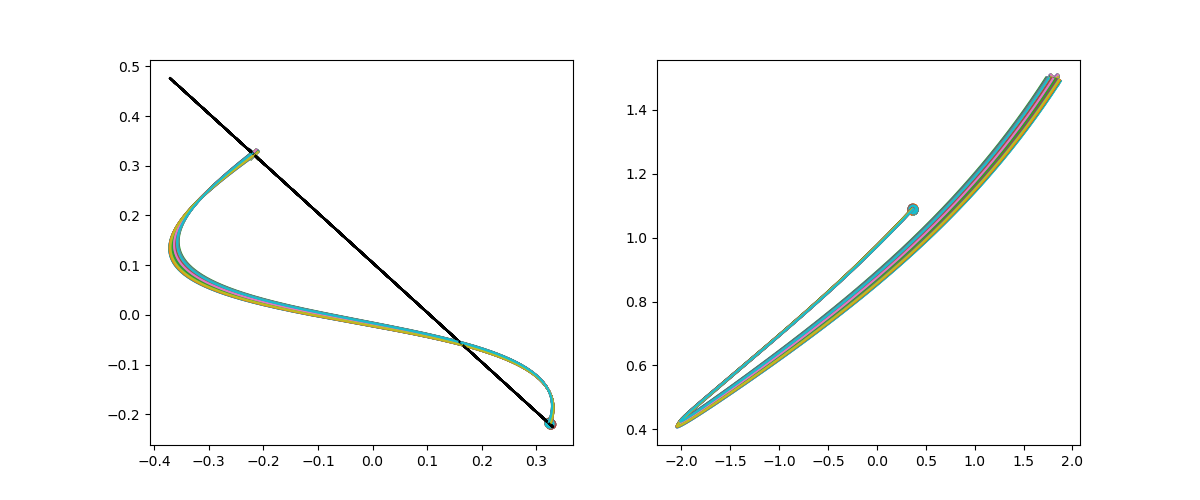

In [195]:
# Make sure all of the points are hitting the guard
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)

a = guard_pts_to_full(guard_pts)
for i in range(0, N, 10):
    x0_pt = a[i, :]
    sol, ts, ys = rollout_sys_to_guard(x0_pt)
    # print(sol.result)
    ax1.scatter(x0_pt[0], x0_pt[1], marker='x') # preimpact starting points
    ax1.scatter(ys[0, 0], ys[0, 1]) # post-impact starting points
    ax1.plot(ys[:, 0], ys[:, 1])
    fig.add_axes(ax1)

    ax2.scatter(x0_pt[2], x0_pt[3], marker='x') # Preimpact starting points
    ax2.scatter(ys[0, 2], ys[0, 3]) # Post-impact starting points
    ax2.plot(ys[:, 2], ys[:, 3])
    fig.add_axes(ax2)
    # print(guard_vmap(ys[-1, :][np.newaxis, :]))
    x_guard = np.linspace(np.min(ys[:, 0]), np.max(ys[:, 0]), 10)
    ax1.plot(x_guard, 2 * sys.gamma - x_guard, 'k:')
    # plt.plot(ys[:, 1], ys[:, 3])

plt.show()
# plt.close()

In [201]:
## Algorithm subroutines for working with Ellipsoids

def reject_and_resample(Ei: Ellipsoid, I, Pxi, rescale=0.99, rescale_strategy = 'const', N_pts=1000) -> Tuple[np.ndarray, Ellipsoid, np.ndarray]:
    in_idx = Ei.contains_point(Pxi.T)
    in_pts = Pxi[in_idx, :]
    out_pts = Pxi[~in_idx, :]
    Ein = Ellipsoid(Pxi.shape[1])
    all_pts = np.vstack((in_pts, Pxi[Ei.contains_point(Pxi.T), :]))
    # all_pts = in_pts
    if(all_pts.shape[1] == 0):
        all_pts = Pxi
    Ein.fit_p_ball(all_pts, 2, verbose=True)
    if rescale_strategy == 'const':
        Ein.scale(rescale) # Enforce contraction rate
    elif rescale_strategy == 'iter':
        while any(Ein.contains_point(out_pts.T)):
            Ein.scale(rescale) # Enforce contraction rate

    return sample_from(Ein, N_pts).T, Ein, all_pts

Optimal value : 21.567546971955988
A* = [[35863.32446266  -721.38601784  8900.16784294]
 [ -721.38601784   197.45245637  -133.46161405]
 [ 8900.16784294  -133.46161405  2574.66550721]]
b* = [[ 0.09547848]
 [-0.02350168]
 [ 0.0049828 ]]
volume proxy: 21.567546971955988
optimal
Optimization succeeded.


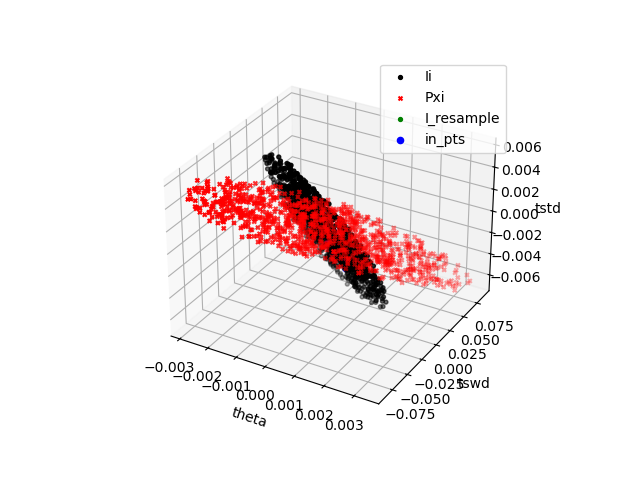

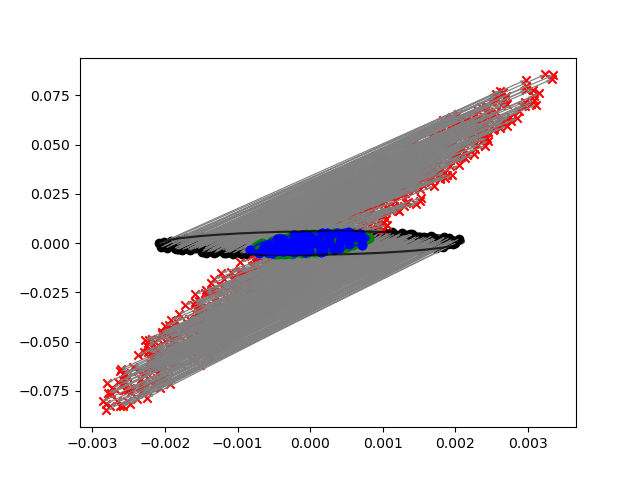

In [214]:
# Test Sampling from Ellipsoid 
# E4 = Ellipsoid(4)
# alpha = np.array([[165.28081557, 113.26623346,  -4.54506446,  36.16299909],
#        [113.26623346, 485.24903395, -29.07552002, 158.31441697],
#        [ -4.54506446, -29.07552002,  29.20983934, -10.56800326],
#        [ 36.16299909, 158.31441697, -10.56800326,  83.72457104]]) 
# E4.Q = alpha.T@alpha
# E4.c = np.array([[ 0.323636  , -0.21863605,  0.37208375,  1.0906425 ]]).T
# full_pts = sample_from(E4, N)
# print(full_pts.shape)

# guard_pts = full_pts_to_guard(full_pts)

# E0 = Ellipsoid(3)
# E0.fit_p_ball(guard_pts, 2)

# Test sample_from
Ii = sample_from(E0, N).T
assert Ii.shape == (N, 3)
Ei = E0
# fig, ax = plt.subplots()
# ax.scatter(Ii[2, :], Ii[3, :])
# plt.show()

# Test reject_and_resample
Pxi = P(Ii)
Ii_full = guard_pts_to_full(Ii)
Pxi_full = guard_pts_to_full(Pxi)

assert jnp.allclose(guard_vmap(Ii_full), 0, atol=5e-7)
assert jnp.allclose(guard_vmap(Pxi_full), 0, atol=5e-7)

assert Pxi.shape == (N, 3)

# P(in_pts) should lie completely within E0
# We want E_resample to tightly wrap in_pts
# P(I_resample) should also lie within E0
I_resample, E_resample, in_pts = reject_and_resample(E0, Ii, Pxi, rescale=0.99, rescale_strategy='iter')

# Pin_points = P(guard_pts_to_full(in_pts).T).T


# Px_resample = P(guard_pts_to_full(I_resample).T).T
fig1, ax1 = plt.subplots()
inds = [0, 1]
ax1.scatter(Ii[:, inds[0]], Ii[:, inds[1]], c='black', marker='o', label='Ii')
ax1.scatter(Pxi[:, inds[0]], Pxi[:, inds[1]], c='red', marker='x', label='Pxi')
ax1.quiver(
    Ii[:, inds[0]],  # X
    Ii[:, inds[1]],  # Y
    Pxi[:, inds[0]]-Ii[:, inds[0]],  # U
    Pxi[:, inds[1]]-Ii[:, inds[1]],  # V
    angles='xy', 
    scale_units='xy',
    scale=1,
    color='gray'
    )
ax1.scatter(I_resample[:, inds[0]], I_resample[:, inds[1]], c='green', marker='o', label='I_resample')
ax1.scatter(in_pts[:, 0], in_pts[:, 1], c='blue', marker='o', label='in_pts')
# ax1.legend()
plot_projection(E0.Q, E0.c.flatten(), 1, ax1, color = 'black', diml = inds[0], dimh=inds[1])
plot_projection(E_resample.Q, E_resample.c.flatten(), 1, ax1, color = 'blue', diml = inds[0], dimh=inds[1])

fig2 = plt.figure()
fig2.clf()
ax2 = fig2.add_subplot(111, projection='3d')

ax2.scatter(Ii[:, 0], Ii[:, 1], Ii[:, 2], c='black', marker='o', s=8, label='Ii')
ax2.scatter(Pxi[:, 0], Pxi[:, 1], Pxi[:, 2], c='red', marker='x', s=8, label='Pxi')
ax2.scatter(I_resample[:, 0], I_resample[:, 1], I_resample[:, 2], c='green', marker='o', s=8, label='I_resample')
ax2.scatter(in_pts[:, 0], in_pts[:, 1], in_pts[:, 2], c='blue', marker='o', label='in_pts')

ax2.set_xlabel('theta')
ax2.set_ylabel('tswd')
ax2.set_zlabel('tstd')
ax2.legend()
plt.show()

# ax2.scatter(Ii_guard[1, :], Ii_guard[2, :], c='black', marker='o')
# ax2.scatter(Pxi_guard[1, :], Pxi_guard[2, :], c='black', marker='x')
# ax2.scatter(I_resample[1, :], I_resample[2, :], c='green', marker='o')
# ax2.scatter(in_pts[1, :], in_pts[2, :], c='blue', marker='o')
# plot_ellipse(E0.Q, E0.c.flatten(), 1, ax2, diml=1, dimh=2, color = 'blue')
# plot_ellipse(E_resample.Q, E_resample.c.flatten(), 1, ax2, diml=1, dimh=2, color = 'green')

# print(E0.Q)
# print(E0.c)
# print(E_resample.Q)
# print(E_resample.c)


In [216]:
# E0 = Ellipsoid(3)
# E0.fit_p_ball(guard_pts, 2)

# Ii = sample_from(E0, N).T
# Ei = E0

PLOT_EVERY = 5
MAX_ITER = 3
i = 0

1
[[ 3.43074754e+17  2.52585033e+15 -1.43703714e+18]
 [ 2.52585033e+15  1.85963387e+13 -1.05800354e+16]
 [-1.43703714e+18 -1.05800354e+16  6.01931822e+18]] [[-6.96987259e-06]
 [-5.22300515e-04]
 [-4.64191703e-06]]
Success! Found Ellipse after 1 iterations:
Q: [[ 3.43074754e+17  2.52585033e+15 -1.43703714e+18]
 [ 2.52585033e+15  1.85963387e+13 -1.05800354e+16]
 [-1.43703714e+18 -1.05800354e+16  6.01931822e+18]], c: [[-6.96987259e-06]
 [-5.22300515e-04]
 [-4.64191703e-06]]


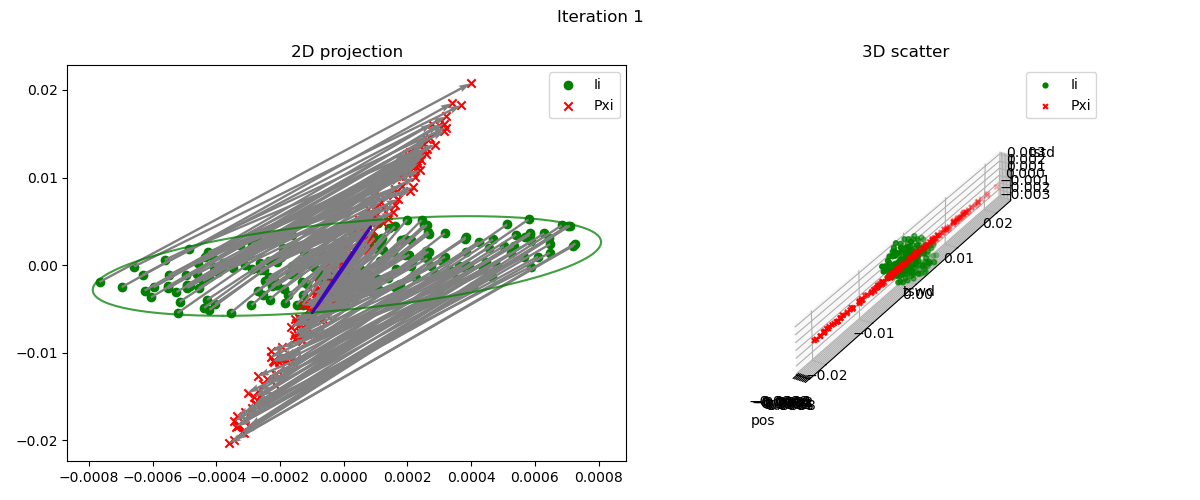

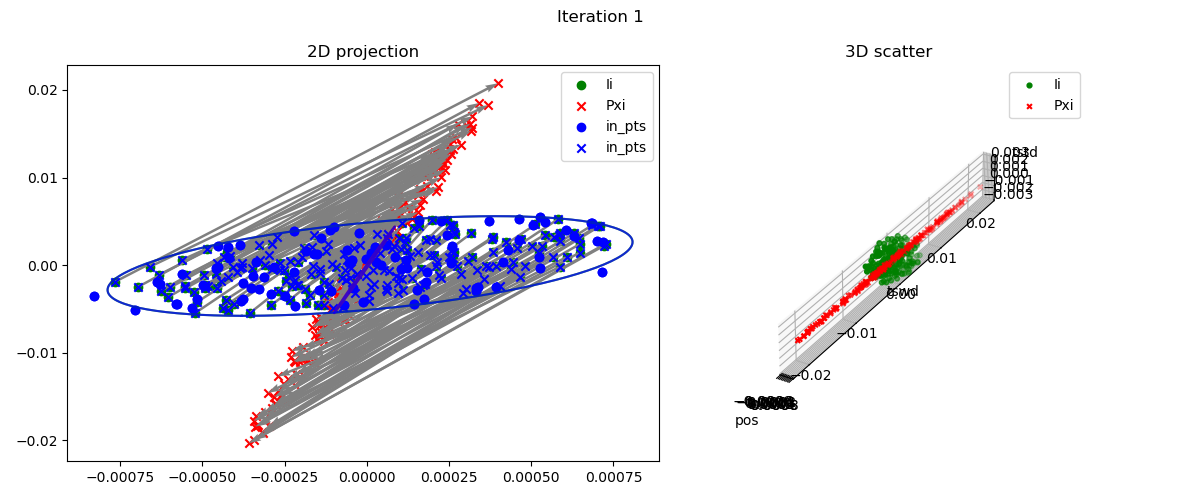

In [218]:
if PLOT:
    fig = plt.figure(figsize=(12, 5))
    ax2d = fig.add_subplot(1, 2, 1)
    ax3d = fig.add_subplot(1, 2, 2, projection='3d')

# Compute PXi = P(Ii)
Pxi = P(Ii)

# If E(PXi) within E(Ii)
Epxi = Ellipsoid(3)
Epxi.fit_p_ball(Pxi, 2)
print(i)
print(Epxi.Q, Epxi.c)

if PLOT:
    # Left subplot: current 2D view
    ax2d.scatter(Ii[::PLOT_EVERY, 0], Ii[::PLOT_EVERY, 1], c='green', marker='o', label="Ii")
    ax2d.scatter(Pxi[::PLOT_EVERY, 0], Pxi[::PLOT_EVERY, 1], c='red', marker='x', label="Pxi")
    ax2d.quiver(
        Ii[::PLOT_EVERY, 0], Ii[::PLOT_EVERY, 1],
        Pxi[::PLOT_EVERY, 0] - Ii[::PLOT_EVERY, 0],
        Pxi[::PLOT_EVERY, 1] - Ii[::PLOT_EVERY, 1],
        angles='xy',
        scale_units='xy',
        scale=1,
        color='gray'
    )
    plot_projection(Ei.Q, Ei.c.flatten(), 1, ax2d, color='green')
    plot_projection(Epxi.Q, Epxi.c.flatten(), 1, ax2d, color='red')
    ax2d.set_title("2D projection")
    ax2d.legend()

    # Right subplot: 3D scatter
    ax3d.scatter(
        Ii[::PLOT_EVERY, 0], Ii[::PLOT_EVERY, 1], Ii[::PLOT_EVERY, 2],
        c='green', marker='o', s=12, label='Ii'
    )
    ax3d.scatter(
        Pxi[::PLOT_EVERY, 0], Pxi[::PLOT_EVERY, 1], Pxi[::PLOT_EVERY, 2],
        c='red', marker='x', s=12, label='Pxi'
    )
    ax3d.set_title("3D scatter")
    ax3d.set_xlabel("pos")
    ax3d.set_ylabel("tswd")
    ax3d.set_zlabel("tstd")
    ax3d.set_aspect("equal")
    ax3d.legend()

if Ei.contains_ellipsoid(Epxi):
    print(f"Success! Found Ellipse after {i} iterations:")
    print(f"Q: {Epxi.Q}, c: {Epxi.c}")
    if PLOT:
        plot_projection(Epxi.Q, Epxi.c.flatten(), 1, ax2d, color='blue')
        plt.suptitle(f"Iteration {i}")
        plt.tight_layout()
        plt.show()
else:
    Ii, Ei, in_pts = reject_and_resample(
        Ei, Ii, Pxi, rescale=0.99, rescale_strategy='iter', N_pts=1000 + 400 * i
    )

if PLOT:
    plt.suptitle(f"Iteration {i}")
    plot_projection(Ei.Q, Ei.c.flatten(), 1, ax2d, color='blue')
    ax2d.scatter(in_pts[:, 0], in_pts[:, 1], c='blue', marker='o', label="in_pts")
    ax2d.scatter(Ii[::PLOT_EVERY, 0], Ii[::PLOT_EVERY, 1], c='blue', marker='x', label="in_pts")
    ax2d.legend()
    plt.tight_layout()
    plt.show()

i += 1